<a href="https://colab.research.google.com/github/MTuan1510/Air-Project/blob/main/06_outliers_chennai_hyderabad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 — Outliers & validity checks: Chennai & Hyderabad
Làm theo **Bước 3–6** của `01_clean_delhi_gurugram.ipynb`, dùng chung `src/utils.py`.

**Quy ước của nhóm:** IQR tính riêng theo từng tháng dương lịch · **chỉ đánh dấu** `<cột>_is_outlier`, không xoá/sửa giá trị gốc · không áp dụng cho `AQI`.

## 0. Môi trường (tự nhận Colab hoặc máy local)

In [1]:
import os, sys

if "google.colab" in sys.modules or os.path.exists("/content"):
    REPO = "/content/Air-Project"
    if not os.path.exists(REPO):
        !git clone https://github.com/MTuan1510/Air-Project.git {REPO}
    else:
        !git -C {REPO} pull
else:
    REPO = os.path.abspath("..")          # chạy local từ thư mục notebooks/

sys.path.append(f"{REPO}/src")
RAW, INTERIM = f"{REPO}/data/raw/city_day.csv", f"{REPO}/data/interim"
PROCESSED, FIGS = f"{REPO}/data/processed", f"{REPO}/reports/figures"
for d in (INTERIM, PROCESSED, FIGS):
    os.makedirs(d, exist_ok=True)
print("Có file after_missing:", all(os.path.exists(f"{INTERIM}/{c}_after_missing.csv") for c in ("chennai", "hyderabad")))

Có file after_missing: True


In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from utils import (audit, flag_outliers_iqr, validity_checks,
                   check_consistency, check_duplicates, clean_city_pipeline)

chennai_clean   = pd.read_csv(f"{INTERIM}/chennai_after_missing.csv",   parse_dates=["Date"])
hyderabad_clean = pd.read_csv(f"{INTERIM}/hyderabad_after_missing.csv", parse_dates=["Date"])
# Nhóm đã chốt: drop Xylene cho cả 8 thành phố. File after_missing của Hyderabad (notebook 03) có thể còn Xylene -> bỏ ở đây cho chắc.
hyderabad_clean = hyderabad_clean.drop(columns=["Xylene"], errors="ignore")
print("Chennai:", chennai_clean.shape, "| Hyderabad:", hyderabad_clean.shape)

Chennai: (2009, 28) | Hyderabad: (2006, 28)


## 1. Đánh dấu outlier (IQR theo tháng)
`flag_outliers_iqr` thêm cột `<cột>_is_outlier`, **không** động vào giá trị gốc.

In [3]:
chennai_outliers   = flag_outliers_iqr(chennai_clean)
hyderabad_outliers = flag_outliers_iqr(hyderabad_clean)

for name, df in [("CHENNAI", chennai_outliers), ("HYDERABAD", hyderabad_outliers)]:
    oc = [c for c in df.columns if c.endswith("_is_outlier")]
    print(f"=== {name}: số ngày bị đánh dấu outlier mỗi cột ===")
    display(df[oc].sum().sort_values(ascending=False))

=== CHENNAI: số ngày bị đánh dấu outlier mỗi cột ===


CO_is_outlier         248
Benzene_is_outlier    207
Toluene_is_outlier    160
NH3_is_outlier        122
NO_is_outlier          95
NO2_is_outlier         79
NOx_is_outlier         76
SO2_is_outlier         70
PM2.5_is_outlier       66
O3_is_outlier          35
PM10_is_outlier        15
dtype: int64

=== HYDERABAD: số ngày bị đánh dấu outlier mỗi cột ===


SO2_is_outlier        128
Toluene_is_outlier    106
PM2.5_is_outlier       98
NH3_is_outlier         88
NO_is_outlier          71
Benzene_is_outlier     60
CO_is_outlier          57
NOx_is_outlier         52
O3_is_outlier          35
PM10_is_outlier        31
NO2_is_outlier         23
dtype: int64

## 2. Validity checks (không âm, ngày không ở tương lai, AQI khớp AQI_Bucket)

In [4]:
for name, df in [("CHENNAI", chennai_outliers), ("HYDERABAD", hyderabad_outliers)]:
    print(f"=== {name}: validity checks ===")
    display(validity_checks(df))

=== CHENNAI: validity checks ===


,rule,n_violations
0,PM2.5 không âm,0
1,PM10 không âm,0
2,NO không âm,0
3,NO2 không âm,0
4,NOx không âm,0
5,NH3 không âm,0
6,CO không âm,0
7,SO2 không âm,0
8,O3 không âm,0
9,Benzene không âm,0


=== HYDERABAD: validity checks ===


,rule,n_violations
0,PM2.5 không âm,0
1,PM10 không âm,0
2,NO không âm,0
3,NO2 không âm,0
4,NOx không âm,0
5,NH3 không âm,0
6,CO không âm,0
7,SO2 không âm,0
8,O3 không âm,0
9,Benzene không âm,0


## 3. Soi các giá trị cực đoan (phần riêng của Chennai/Hyderabad)
Ở bước missing đã ghi nhận **Chennai Benzene/Toluene có giá trị cực đoan năm 2015** (Benzene tới ~392).
Mục tiêu của ô này: xem đó là *lỗi cảm biến* hay *sự kiện thật* — nhưng **chưa xoá**, chỉ ghi nhận bằng chứng để chốt khi gộp 8 thành phố.

In [5]:
# Benzene / Toluene của Chennai theo năm: nếu median 2015 cao hẳn so với các năm sau -> nghi lỗi hiệu chuẩn cảm biến
yr = chennai_outliers.groupby(chennai_outliers["Date"].dt.year)[["Benzene", "Toluene"]].agg(["median", "max", "count"]).round(1)
display(yr)

print("Top 10 Benzene lớn nhất ở Chennai:")
display(chennai_outliers.nlargest(10, "Benzene")[["Date", "Benzene", "Toluene", "CO", "PM2.5"]])

print("Top 10 PM2.5 lớn nhất ở Hyderabad:")
display(hyderabad_outliers.nlargest(10, "PM2.5")[["Date", "PM2.5", "PM10", "AQI"]])

Benzene              Toluene             
      median    max count  median    max count
Date                                          
2015     3.2  391.9   246     4.7  266.0   304
2016     1.4   17.5   346     3.8   27.1   347
2017     0.1    5.8   365     0.0    5.8   365
2018     0.2    4.8   313     2.1   24.9   365
2019     0.1   10.7   365     0.9   28.0   365
2020     0.3   29.0   183     0.0    1.3   166

Top 10 Benzene lớn nhất ở Chennai:


,Date,Benzene,Toluene,CO,PM2.5
167,2015-06-17,391.880000,2.340000,1.97,53.53
241,2015-08-30,287.490000,1.190000,1.54,37.62
242,2015-08-31,264.515556,1.114667,1.43,41.00
243,2015-09-01,241.541111,1.039333,1.21,32.37
240,2015-08-29,240.885000,4.835000,2.19,43.58
244,2015-09-02,218.566667,0.964000,4.70,24.27
245,2015-09-03,195.592222,0.888667,1.99,26.54
239,2015-08-28,194.280000,8.480000,1.54,45.16
246,2015-09-04,172.617778,0.813333,1.92,26.96
247,2015-09-05,149.643333,0.738000,2.01,25.83


Top 10 PM2.5 lớn nhất ở Hyderabad:


,Date,PM2.5,PM10,AQI
529,2016-06-16,571.02,NaN,737.0
149,2015-06-02,539.13,NaN,661.0
413,2016-02-21,525.09,94.00,442.0
299,2015-10-30,516.20,82.97,487.0
171,2015-06-24,467.67,NaN,348.0
528,2016-06-15,363.14,NaN,199.0
554,2016-07-11,357.85,NaN,307.0
414,2016-02-22,353.58,95.54,510.0
229,2015-08-21,299.25,NaN,316.0
300,2015-10-31,270.21,104.38,502.0


## 4. Biểu đồ minh hoạ (lưu vào `reports/figures/`)

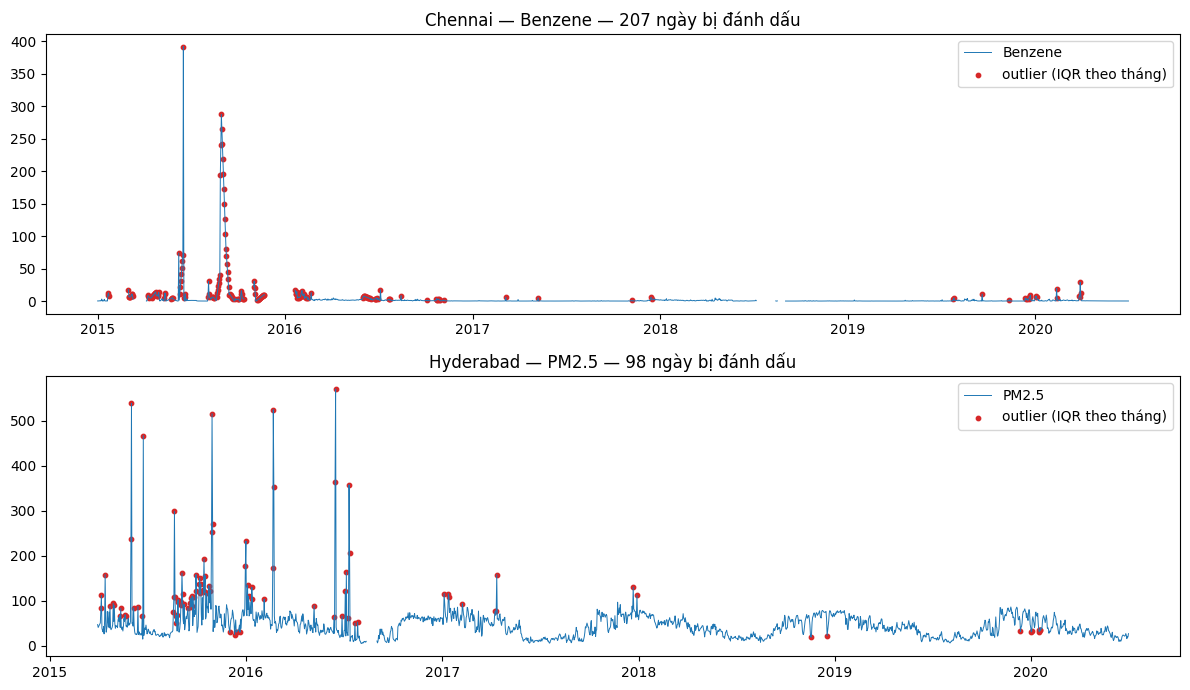

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
for ax, (df, col, title) in zip(axes, [(chennai_outliers, "Benzene", "Chennai — Benzene"),
                                       (hyderabad_outliers, "PM2.5", "Hyderabad — PM2.5")]):
    flag = df[f"{col}_is_outlier"]
    ax.plot(df["Date"], df[col], lw=0.7, color="tab:blue", label=col)
    ax.scatter(df.loc[flag, "Date"], df.loc[flag, col], s=10, color="tab:red", label="outlier (IQR theo tháng)")
    ax.set_title(f"{title} — {int(flag.sum())} ngày bị đánh dấu"); ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(f"{FIGS}/outliers_chennai_hyderabad.png", dpi=130)
plt.show()

## 5. Lưu checkpoint sau Outliers

In [7]:
chennai_outliers.to_csv(f"{INTERIM}/chennai_after_outliers.csv", index=False)
hyderabad_outliers.to_csv(f"{INTERIM}/hyderabad_after_outliers.csv", index=False)
print("Chennai:", chennai_outliers.shape, "| Hyderabad:", hyderabad_outliers.shape)

Chennai: (2009, 39) | Hyderabad: (2006, 39)


## 6. Consistency & Deduplicate

In [8]:
for name, df in [("CHENNAI", chennai_outliers), ("HYDERABAD", hyderabad_outliers)]:
    issues = check_consistency(df)
    print(f"=== {name} ===")
    print("Consistency issues:", issues if issues else "Không có vấn đề")
    print("Số dòng trùng (City+Date):", check_duplicates(df), "\n")

=== CHENNAI ===
Consistency issues: Không có vấn đề
Số dòng trùng (City+Date): 0 

=== HYDERABAD ===
Consistency issues: Không có vấn đề
Số dòng trùng (City+Date): 0 



## 7. Audit cuối + checkpoint `after_w4`

In [9]:
for name, df in [("CHENNAI", chennai_outliers), ("HYDERABAD", hyderabad_outliers)]:
    print(f"=== {name}: audit cuối cùng ===")
    display(audit(df).sort_values("pct_missing", ascending=False).head(15))

chennai_outliers.to_csv(f"{INTERIM}/chennai_after_w4.csv", index=False)
hyderabad_outliers.to_csv(f"{INTERIM}/hyderabad_after_w4.csv", index=False)

=== CHENNAI: audit cuối cùng ===


,dtype,n_missing,pct_missing,n_unique
PM10,float64,1698,84.5,306
NH3,float64,411,20.5,1507
Benzene,float64,191,9.5,555
AQI_Bucket,str,125,6.2,6
AQI,float64,125,6.2,234
PM2.5,float64,98,4.9,1688
Toluene,float64,97,4.8,832
NO,float64,17,0.8,1034
SO2,float64,17,0.8,1049
NOx,float64,17,0.8,1293


=== HYDERABAD: audit cuối cùng ===


,dtype,n_missing,pct_missing,n_unique
NH3,float64,338,16.8,1167
PM10,float64,332,16.6,1577
Benzene,float64,129,6.4,447
Toluene,float64,129,6.4,1109
AQI,float64,126,6.3,227
AQI_Bucket,str,126,6.3,6
PM2.5,float64,105,5.2,1704
CO,float64,60,3.0,177
NO,float64,19,0.9,1046
NOx,float64,19,0.9,1495


## 8. Đóng gói bằng `clean_city_pipeline` + kiểm tra schema khi gộp
✅ **Xylene:** nhóm trưởng đã chốt **drop cho cả 8 thành phố** → cả Chennai và Hyderabad đều truyền `drop_cols=["Xylene"]` để schema đồng nhất khi gộp.

In [10]:
chennai_final   = clean_city_pipeline("Chennai",   raw_path=RAW, drop_cols=["Xylene"], save_dir=PROCESSED)
print()
hyderabad_final = clean_city_pipeline("Hyderabad", raw_path=RAW, drop_cols=["Xylene"], save_dir=PROCESSED)

--- Xử lý Missing Values cho Chennai ---
  - CO: phát hiện 40 ngày flatline (0 liên tục >= 3 ngày) -> NaN
  - Benzene: phát hiện 137 ngày flatline (0 liên tục >= 3 ngày) -> NaN
  - Toluene: phát hiện 143 ngày flatline (0 liên tục >= 3 ngày) -> NaN
  - Đã xoá cột (đề xuất, cần nhóm đồng ý): ['Xylene']
  => Còn 2705 ô missing SAU xử lý (CHỦ Ý giữ NaN ở khối trống dài, không bịa số)


  - Consistency: không có vấn đề
  - Dòng trùng (City+Date): 0
  -> Đã lưu /home/claude/scratch/Air-Project-main/data/processed/chennai_clean.csv

--- Xử lý Missing Values cho Hyderabad ---
  - NOx: phát hiện 18 ngày flatline (0 liên tục >= 3 ngày) -> NaN
  - CO: phát hiện 67 ngày flatline (0 liên tục >= 3 ngày) -> NaN
  - Benzene: phát hiện 23 ngày flatline (0 liên tục >= 3 ngày) -> NaN
  - Toluene: phát hiện 14 ngày flatline (0 liên tục >= 3 ngày) -> NaN
  - Xylene: phát hiện 14 ngày flatline (0 liên tục >= 3 ngày) -> NaN
  - Đã xoá cột (đề xuất, cần nhóm đồng ý): ['Xylene']
  => Còn 1314 ô missing SAU xử lý (CHỦ Ý giữ NaN ở khối trống dài, không bịa số)


  - Consistency: không có vấn đề
  - Dòng trùng (City+Date): 0
  -> Đã lưu /home/claude/scratch/Air-Project-main/data/processed/hyderabad_clean.csv


In [11]:
print("Chennai:", len(chennai_final), "dòng,", chennai_final.shape[1], "cột")
print("Hyderabad:", len(hyderabad_final), "dòng,", hyderabad_final.shape[1], "cột")

# So schema với phần của nhóm trưởng (Delhi) để phát hiện sớm lệch cột khi gộp
delhi_ref = pd.read_csv(f"{PROCESSED}/delhi_clean.csv", nrows=5)
for name, df in [("Chennai", chennai_final), ("Hyderabad", hyderabad_final)]:
    print(f"\n{name} vs Delhi -> chỉ có ở {name}:", sorted(set(df.columns) - set(delhi_ref.columns)),
          "| chỉ có ở Delhi:", sorted(set(delhi_ref.columns) - set(df.columns)))

preview = pd.concat([chennai_final, hyderabad_final], ignore_index=True)
print("\nGộp thử:", len(preview), "dòng (phải =", len(chennai_final) + len(hyderabad_final), ")")

Chennai: 2009 dòng, 39 cột
Hyderabad: 2006 dòng, 39 cột

Chennai vs Delhi -> chỉ có ở Chennai: [] | chỉ có ở Delhi: []

Hyderabad vs Delhi -> chỉ có ở Hyderabad: [] | chỉ có ở Delhi: []

Gộp thử: 4015 dòng (phải = 4015 )


#  9.Lưu và tải về máy

In [12]:
chennai_outliers.to_csv(f"{INTERIM}/chennai_after_outliers.csv", index=False)
hyderabad_outliers.to_csv(f"{INTERIM}/hyderabad_after_outliers.csv", index=False)
print("Chennai:", chennai_outliers.shape, "| Hyderabad:", hyderabad_outliers.shape)

# Chỉ tải về máy khi đang chạy trên Colab; chạy local thì file đã nằm sẵn trong data/interim/
try:
    from google.colab import files
    files.download(f"{INTERIM}/chennai_after_outliers.csv")
    files.download(f"{INTERIM}/hyderabad_after_outliers.csv")
except ImportError:
    print("Chạy local: file đã lưu ở", INTERIM)

Chennai: (2009, 39) | Hyderabad: (2006, 39)
Chạy local: file đã lưu ở /home/claude/scratch/Air-Project-main/data/interim
